# Sparsification across the other uncertainty sources

Companion to `sparsification_classic.ipynb`, which covers only each head's OWN uncertainty on `pr_classic3`. This one collects the same numbers for the other uncertainty sources: MC-dropout, Laplace, the deep ensemble, and the STimage readout.

It is a **table**, not a figure. The paper's sparsification figure stays the own-head one; these numbers back the sentence "The epistemic terms perform no better, and STimage recovers 5% to 10%".

## Why a separate notebook

The sources sit under different run_ids with a different path shape: MC-dropout and Laplace replay `pr_classic1`, the deep ensemble is `de_6` and STimage is `sti_v1`, and the ensemble tree goes through `.../<model>/ensemble/canal2_uncertainty/<source>/` with **no** `lambda_` level. Folding all of that into the figure notebook would double its config for numbers that never appear in the figure.

**The arms are not the same weights.** MC-dropout and Laplace replay `pr_classic1`, the own head is read on `pr_classic3`, the ensemble is `de_6`. The first two are launches of the same sweep (measured gap ~0.002); the ensemble is a separate training, so comparing it mixes estimator and checkpoint. Same caveat as `unc_error_correlations_epistemics.ipynb`.

## What it reports

For each (source, cohort, head), on both per-(gene, slide) protocols and on the global one:

```
AUSE(s) = (1/19) sum_f  curve_s(f) / curve_s(0)      # 1.0 = uninformative, lower is better
share   = (1 - AUSE(pred)) / (1 - AUSE(oracle))      # "recovers X% of the oracle reduction"
```

plus `share mu_h`, the same share for the PREDICTED MEAN used alone as the score, the baseline a head has to beat to carry anything of its own.

**Missing runs are skipped and named, never silently dropped.** A source whose artifact is absent, or does not carry the per-(gene, slide) columns, is listed by name in the collect cell, and the table is built from what is there.

In [7]:
import sys
import json
from pathlib import Path

import numpy as np
import pandas as pd

PROJ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
sys.path.append(str(PROJ))
RESULTS = PROJ / "results"

# =============================== SETTINGS ====================================
DATASETS = ["10x_TuPro", "TLS", "LUNG_CANCER"]
RADIUS   = "r75"
LAM      = "lambda_0.0"      # the Gaussians of the single-model tree; 0.0 IS the proper NLL
# The 4 heads of the figure. 'homoscedastic' is excluded here for the SAME reason as there:
# one sigma per gene orders nothing WITHIN a gene, so its curve is defined on half the
# fractions only and its AUSE would rest on a truncated support.
HEADS    = ["heteroscedastic", "spot_homoscedastic", "poisson_cp",
            "negativebinomial_hetero_noanchor_cp"]
STI_HEADS = ["STI_nb_cp", "STI_nb_raw"]
SPARS_CASES = ["lin_all", "lin_pos"]
PROTOCOLS   = ["gene_slide", "gene_slide_bin", "pooled"]
# =============================================================================

CONVENTION = "v3_native_scale"
SCORES = ["pred", "oracle", "mu_high", "mu_low"]
PROTOCOL_LABEL = {"gene_slide": "within (gene, slide)",
                  "gene_slide_bin": "within (gene, slide, mean bin)",
                  "pooled": "global, no grouping"}
DATASET_LABELS = {"10x_TuPro": "Tumor Profiler", "TLS": "Kidney/Lung with TLS",
                  "LUNG_CANCER": "NSCLC"}
HEAD_LABELS = {"heteroscedastic": "Gaussian heteroscedastic",
               "spot_homoscedastic": "Gaussian spot-homoscedastic",
               "poisson_cp": "Poisson",
               "negativebinomial_hetero_noanchor_cp": "Negative binomial",
               "STI_nb_cp": "STimage head", "STI_nb_raw": "STimage head, raw counts"}

# ONE entry per uncertainty column of the paper. `ens` gives the SHAPE of the path, not only
# the origin: the ensemble tree goes through <model>/ensemble/<sub>/ and carries NO lambda_
# level, whereas the single-model tree carries one for the Gaussians.
SOURCES = [
    dict(key="own",     label="own head (pr_classic3)",      run="pr_classic3", rid="pr_classic3",
         sub="canal2_uncertainty",                 ens=False, heads=HEADS),
    dict(key="mc",      label="MC-dropout, epistemic",       run="pr_classic1", rid="pr_classic1",
         sub="canal2_epistemic",                   ens=False, heads=HEADS),
    dict(key="laplace", label="Laplace, epistemic",          run="pr_classic1", rid="pr_classic1",
         sub="canal2_laplace_epistemic",           ens=False, heads=HEADS),
    dict(key="de_ale",  label="Deep ensemble, aleatoric",    run="de_6", rid="de_6",
         sub="canal2_uncertainty/aleatoric",       ens=True,  heads=HEADS),
    dict(key="de_epi",  label="Deep ensemble, epistemic",    run="de_6", rid="de_6",
         sub="canal2_uncertainty/epistemic",       ens=True,  heads=HEADS),
    dict(key="de_tot",  label="Deep ensemble, total",        run="de_6", rid="de_6",
         sub="canal2_uncertainty/total",           ens=True,  heads=HEADS),
    dict(key="sti_ale", label="STimage, aleatoric",          run="sti_v1", rid="sti_v1",
         sub="canal2_uncertainty/aleatoric",       ens=True,  heads=STI_HEADS),
    dict(key="sti_epi", label="STimage, epistemic",          run="sti_v1", rid="sti_v1",
         sub="canal2_uncertainty/epistemic",       ens=True,  heads=STI_HEADS),
]


def curve_col(score, protocol, case):
    return f"curve_{score}_{protocol}_{case}"


def canal2_dir(src, ds, head):
    """The canal 2 path for (source, cohort, head), or None if it does not exist.

    The lambda_ level exists only in the single-model tree AND only for the Gaussians,
    so both are tried rather than hardcoding which heads carry one: the list of Gaussian
    heads would be one more thing to keep in sync for nothing."""
    base = RESULTS / ds / src["rid"] / f"_{ds}_hvg_top3000" / RADIUS / head
    cands = [base / "ensemble" / src["sub"]] if src["ens"] else [base / src["sub"],
                                                                 base / LAM / src["sub"]]
    for c in cands:
        if (c / "summary.json").is_file():
            return c
    return None


def ause(curve):
    """Area under the curve normalized by its start, taken as the MEAN over the 19 fractions
    (they are equally spaced), so that a non-informative sort gives exactly 1.0. It is that
    normalization which makes `share` zero for a score carrying no information.

    Returns NaN if the curve is not defined EVERYWHERE: nanmean over a truncated support would
    give a number that looks complete and is not."""
    c = np.asarray(curve, dtype=float)
    if c.size == 0 or not np.isfinite(c).all() or c[0] == 0:
        return float("nan")
    return float(np.mean(c / c[0]))


rows, missing, stale = [], [], []
for src in SOURCES:
    for ds in DATASETS:
        for head in src["heads"]:
            d = canal2_dir(src, ds, head)
            if d is None:
                missing.append((src["label"], ds, head))
                continue
            s = json.loads((d / "summary.json").read_text())
            if s.get("not_applicable"):
                continue
            sp_path = d / "sparsification.parquet"
            if s.get("canal2_convention") != CONVENTION or not sp_path.is_file():
                stale.append((src["label"], ds, head, s.get("canal2_convention")))
                continue
            sp = pd.read_parquet(sp_path)
            # The column test is done ONCE per run, before the loop over cases: inside it
            # would report the same run once per case and duplicate the DROPPED list.
            need_all = [curve_col(x, p, c) for x in SCORES for p in PROTOCOLS for c in SPARS_CASES]
            if any(c not in sp.columns for c in need_all):
                stale.append((src["label"], ds, head, "old sparsification columns"))
                continue
            for case in SPARS_CASES:
                for proto in PROTOCOLS:
                    need = {x: curve_col(x, proto, case) for x in SCORES}
                    rec = dict(source=src["key"], source_label=src["label"], dataset=ds,
                               head=head, case=case, protocol=proto)
                    for x, c in need.items():
                        rec[f"ause_{x}"] = ause(sp[c].to_numpy())
                    o = rec["ause_oracle"]
                    for x in ("pred", "mu_high", "mu_low"):
                        rec[f"share_{x}"] = ((1 - rec[f"ause_{x}"]) / (1 - o)
                                             if np.isfinite(o) and abs(1 - o) > 1e-9 else float("nan"))
                    # THE honest baseline: the BEST of the two mu directions, cell by
                    # cell. The two do not agree on which is stronger, so reporting only
                    # one would amount to picking the one that flatters the source, and a
                    # other direction would flatter the head. Same convention as in the figure notebook.
                    hi, lo = rec["share_mu_high"], rec["share_mu_low"]
                    rec["share_mu_best"] = (np.nanmax([hi, lo]) if np.isfinite([hi, lo]).any()
                                            else float("nan"))
                    rec["mu_best_dir"] = ("high" if (np.isfinite(hi) and (not np.isfinite(lo) or hi >= lo))
                                          else "low" if np.isfinite(lo) else "-")
                    fr = sp["frac"].to_numpy()
                    cur = sp[need["pred"]].to_numpy()
                    for f in (0.20, 0.50):
                        k = int(np.argmin(np.abs(fr - f)))
                        rec[f"drop_{int(f*100)}pct"] = (100.0 * (1.0 - cur[k] / cur[0])
                                                        if cur[0] else float("nan"))
                    rows.append(rec)

TAB = pd.DataFrame(rows)
print(f"{len(TAB):,} rows collected, "
      f"{TAB['source'].nunique() if len(TAB) else 0} source(s) present.")
if missing:
    print(f"\n{len(missing)} (source, cohort, head) MISSING - job not launched, failed, or still running:")
    for lbl, ds, h in missing:
        print(f"    {lbl:<30s} {ds:<12s} {h}")
if stale:
    print(f"\n(!) {len(stale)} run(s) DROPPED - the artifact exists but does not carry the")
    print(f"    per-(gene, slide) sparsification columns:")
    for lbl, ds, h, why in stale:
        print(f"    {lbl:<30s} {ds:<12s} {h:<38s} {why!r}")
# Coverage per source, TO BE READ BEFORE the tables: a source with a smaller n does not cover
# fewer models by nature, it is missing jobs.
if len(TAB):
    print("\ncoverage per source (cohort, head):")
    for src in SOURCES:
        n = len(TAB[(TAB["source"] == src["key"]) & (TAB["case"] == SPARS_CASES[0])
                    & (TAB["protocol"] == PROTOCOLS[0])])
        full = len(DATASETS) * len(src["heads"])
        print(f"    {src['label']:<30s} {n:>2d}/{full:<2d}"
              + ("" if n == full else "   <-- INCOMPLET"))

468 rows collected, 8 source(s) present.

(!) 6 run(s) DROPPED - the artifact exists but does not carry the
    per-(gene, slide) sparsification columns:
    Laplace, epistemic             10x_TuPro    poisson_cp                             'old sparsification columns'
    Laplace, epistemic             10x_TuPro    negativebinomial_hetero_noanchor_cp    'old sparsification columns'
    Laplace, epistemic             TLS          poisson_cp                             'old sparsification columns'
    Laplace, epistemic             TLS          negativebinomial_hetero_noanchor_cp    'old sparsification columns'
    Laplace, epistemic             LUNG_CANCER  poisson_cp                             'old sparsification columns'
    Laplace, epistemic             LUNG_CANCER  negativebinomial_hetero_noanchor_cp    'old sparsification columns'

coverage per source (cohort, head):
    own head (pr_classic3)         12/12
    MC-dropout, epistemic          12/12
    Laplace, epistemic         

## Three views, one cell each

The full output is several hundred lines, so it is split rather than scrolled:

| cell | view | what it is for |
|---|---|---|
| VIEW 1 | `lin_all`, per-(gene, slide) | the whole panel, zeros included |
| VIEW 2 | `lin_pos`, per-(gene, slide) | detected entries only — **the numbers the main text quotes** |
| VIEW 3 | `pooled`, both cases | the global sort, kept as a demonstration of the confound |

Each view prints the same three blocks: the integrated table, the per-source range, and the share fraction by fraction.

**`share pred` is the number the paper quotes.** `share mu_h` is the same share computed with the predicted mean used alone as the removal score, the redundancy baseline: where `share pred` does not exceed `share mu_h`, that source recovers no more of the oracle than the mean it is already conditioned on.

**Expect VIEW 3 to show much larger numbers than VIEW 1 and VIEW 2.** That is the result, not an improvement. With no grouping, a head scores well by knowing which *genes* are hard rather than which spots are wrong, and `share mu_h` there shows the predicted mean alone already captures most of the oracle. Never quote a VUE 3 number as an abstention performance.

A row absent from a table means that job has not landed; it is named in the collect cell above rather than dropped.

In [8]:
# ── The display functions, defined ONCE, called by the three cells that follow ──
# One cell per view rather than one block: the full output is hundreds of lines and
# a comparison cannot be followed by scrolling through it.

FRAC_SHOW = [0.10, 0.20, 0.30, 0.40, 0.50, 0.60, 0.70, 0.80, 0.90]


def share_per_frac(sp, proto, case, score="pred"):
    """share(f) = (1 - pred(f)/pred(0)) / (1 - oracle(f)/oracle(0)) at the fractions of FRAC_SHOW.

    Same quantity as the 'share pred' column, but BEFORE integrating over the fractions. f = 0 is
    omitted: both falls are 0 there, so share(0) is 0/0. None if the curve is not usable."""
    cp, co = curve_col(score, proto, case), curve_col("oracle", proto, case)
    if cp not in sp.columns or co not in sp.columns:
        return None
    fr = sp["frac"].to_numpy()
    p, o = sp[cp].to_numpy(), sp[co].to_numpy()
    if not np.isfinite(p[0]) or not np.isfinite(o[0]) or p[0] == 0 or o[0] == 0:
        return None
    out = []
    for f in FRAC_SHOW:
        k = int(np.argmin(np.abs(fr - f)))
        num, den = 1.0 - p[k] / p[0], 1.0 - o[k] / o[0]
        out.append(100.0 * num / den if abs(den) > 1e-12 else np.nan)
    return np.array(out)


def show_view(cases, protos, per_frac=True):
    """ONE view: the integrated table, the per-source summary, and the share recovered fraction by fraction.

    `cases` and `protos` are lists, so that one can ask for 'one case over the two
    per-(gene, slide) protocols' as well as 'the global protocol over the two cases'."""
    if TAB.empty:
        print("nothing to show: no readable sparsification.parquet for these sources.")
        return

    for case in cases:
        for proto in protos:
            sub = TAB[(TAB["case"] == case) & (TAB["protocol"] == proto)]
            if sub.empty:
                continue
            print("=" * 150)
            print(f"{case}  |  {PROTOCOL_LABEL[proto]}")
            print("  share pred = (1 - AUSE pred) / (1 - AUSE oracle): the share of the REDUCTION the")
            print("               oracle obtains that this score recovers.")
            print("  share mu* = THE baseline: the BEST of the two directions of the predicted mean")
            print("               alone, with the direction kept alongside.")
            print("=" * 150)
            for ds in DATASETS:
                s2 = sub[sub["dataset"] == ds]
                if s2.empty:
                    continue
                print(f"\n--- {DATASET_LABELS.get(ds, ds)} ---")
                print(f"  {'source':<30s} {'head':<30s} {'AUSE pred':>10s} {'AUSE orac':>10s} "
                      f"{'share pred':>10s} {'share mu_h':>10s} {'share mu_l':>10s} {'share mu*':>9s} "
                      f"{'dir':>5s} {'drop20%':>9s} {'drop50%':>9s}")
                for src in SOURCES:
                    for head in src["heads"]:
                        r = s2[(s2["source"] == src["key"]) & (s2["head"] == head)]
                        if r.empty:
                            continue
                        r = r.iloc[0]
                        print(f"  {src['label']:<30s} {HEAD_LABELS.get(head, head):<30s} "
                              f"{r['ause_pred']:>10.4f} {r['ause_oracle']:>10.4f} "
                              f"{r['share_pred']:>9.1%} {r['share_mu_high']:>9.1%} "
                              f"{r['share_mu_low']:>9.1%} {r['share_mu_best']:>8.1%} "
                              f"{r['mu_best_dir']:>5s} "
                              f"{r['drop_20pct']:>8.2f}% {r['drop_50pct']:>8.2f}%")

    # The SUMMARY the main text quotes: a RANGE per source, not a mean. The cohorts
    # are not interchangeable and the paper already reports ranges.
    print("\n" + "=" * 150)
    print("SUMMARY FOR THE TEXT: range of 'share pred' per source, and of 'share mu*' alongside")
    print("  n = number of (cohort, head) present. An n SMALLER than the others means jobs are")
    print("  missing, NOT that the source covers fewer models by nature.")
    print("  beats mu = number of cells where share pred exceeds share mu*.")
    print("=" * 150)
    for case in cases:
        for proto in protos:
            if TAB[(TAB["case"] == case) & (TAB["protocol"] == proto)].empty:
                continue
            print(f"\n--- {case} | {PROTOCOL_LABEL[proto]} ---")
            for src in SOURCES:
                s2 = TAB[(TAB["case"] == case) & (TAB["protocol"] == proto)
                         & (TAB["source"] == src["key"])].dropna(subset=["share_pred"])
                if s2.empty:
                    print(f"  {src['label']:<30s} -- no run")
                    continue
                p, mu = s2["share_pred"], s2["share_mu_best"]
                win = int((p > mu).sum())
                print(f"  {src['label']:<30s} share pred {p.min():+6.1%} to {p.max():+6.1%}   "
                      f"(mu* {mu.min():+6.1%} a {mu.max():+6.1%})   "
                      f"beats mu {win}/{len(s2)}   n={len(s2)}")

    if not per_frac:
        return
    print("\n" + "=" * 150)
    print("SHARE OF THE ORACLE RECOVERED, FRACTION BY FRACTION (%)")
    print("  0 % = non-informative; 100 % = as good as the oracle at that fraction;")
    print("  a NEGATIVE value says the sort is worse than random.")
    print("=" * 150)
    for case in cases:
        for proto in protos:
            for ds in DATASETS:
                hdr = False
                for src in SOURCES:
                    for head in src["heads"]:
                        d = canal2_dir(src, ds, head)
                        if d is None or not (d / "sparsification.parquet").is_file():
                            continue
                        v = share_per_frac(pd.read_parquet(d / "sparsification.parquet"),
                                           proto, case, "pred")
                        if v is None:
                            continue
                        if not hdr:
                            print(f"\n--- {case} | {PROTOCOL_LABEL[proto]} | "
                                  f"{DATASET_LABELS.get(ds, ds)} ---")
                            print(f"  {'source':<28s} {'head':<28s} "
                                  + "".join(f"{int(100*f):>7d}%" for f in FRAC_SHOW))
                            hdr = True
                        print(f"  {src['label']:<28s} {HEAD_LABELS.get(head, head):<28s} "
                              + "".join(f"{x:>8.1f}" for x in v))


print("show_view(cases, protos) ready. The three cells that follow are its three views.")

show_view(cases, protos) ready. The three cells that follow are its three views.


In [9]:
# ═══ VIEW 1: lin_all, ALL entries (zeros included), per-(gene, slide) protocols ═════════════
# The complete panel, the one a practitioner would actually withhold on. At an undetected
# entry the error IS the prediction, so any score that follows mu sorts partly by the error:
# that is why 'share mu_h' is the column to read alongside 'share pred' here.
show_view(["lin_all"], ["gene_slide", "gene_slide_bin"])

lin_all  |  within (gene, slide)
  share pred = (1 - AUSE pred) / (1 - AUSE oracle): the share of the REDUCTION the
               oracle obtains that this score recovers.
  share mu* = THE baseline: the BEST of the two directions of the predicted mean
               alone, with the direction kept alongside.

--- Tumor Profiler ---
  source                         head                            AUSE pred  AUSE orac share pred share mu_h share mu_l share mu*   dir   drop20%   drop50%
  own head (pr_classic3)         Gaussian heteroscedastic           0.8943     0.5070     21.4%     19.7%    -27.7%    19.7%  high     7.22%    12.08%
  own head (pr_classic3)         Gaussian spot-homoscedastic        0.9399     0.5012     12.0%     19.1%    -28.5%    19.1%  high     4.29%     7.04%
  own head (pr_classic3)         Poisson                            0.8192     0.4731     34.3%     34.3%    -44.2%    34.3%  high    12.29%    20.59%
  own head (pr_classic3)         Negative binomial        

In [10]:
# ═══ VIEW 2: lin_pos, DETECTED entries only (y > 0), per-(gene, slide) protocols ════════════
# The restriction, justified by what view 1 shows. THIS view is where the main text's
# numbers come from, since this is the protocol the paper's figure draws.
show_view(["lin_pos"], ["gene_slide", "gene_slide_bin"])

lin_pos  |  within (gene, slide)
  share pred = (1 - AUSE pred) / (1 - AUSE oracle): the share of the REDUCTION the
               oracle obtains that this score recovers.
  share mu* = THE baseline: the BEST of the two directions of the predicted mean
               alone, with the direction kept alongside.

--- Tumor Profiler ---
  source                         head                            AUSE pred  AUSE orac share pred share mu_h share mu_l share mu*   dir   drop20%   drop50%
  own head (pr_classic3)         Gaussian heteroscedastic           0.9386     0.5274     13.0%     -4.9%     -2.2%    -2.2%   low     4.85%     7.78%
  own head (pr_classic3)         Gaussian spot-homoscedastic        0.9189     0.5253     17.1%     -6.3%     -0.8%    -0.8%   low     6.09%     9.53%
  own head (pr_classic3)         Poisson                            0.9425     0.4859     11.2%     11.2%    -19.7%    11.2%  high     5.98%     8.19%
  own head (pr_classic3)         Negative binomial        

In [11]:
# ═══ VIEW 3: the GLOBAL protocol, on both cases ═════════════════════════════════════════════
# One sort over all the cohort's entries, with no grouping. The numbers there are much
# LARGER than in the two previous views, and that is the result, not an
# improvement: with no grouping, a head wins by knowing which GENES are hard rather than
# which spots are wrong. The 'share mu_h' column says it directly -- the predicted mean alone
# already recovers most of the oracle there. To be read as a demonstration of the confound,
# never as the head's abstention performance.
show_view(["lin_all", "lin_pos"], ["pooled"])

lin_all  |  global, no grouping
  share pred = (1 - AUSE pred) / (1 - AUSE oracle): the share of the REDUCTION the
               oracle obtains that this score recovers.
  share mu* = THE baseline: the BEST of the two directions of the predicted mean
               alone, with the direction kept alongside.

--- Tumor Profiler ---
  source                         head                            AUSE pred  AUSE orac share pred share mu_h share mu_l share mu*   dir   drop20%   drop50%
  own head (pr_classic3)         Gaussian heteroscedastic           0.5404     0.3298     68.6%     70.1%    -68.5%    70.1%  high    19.32%    48.20%
  own head (pr_classic3)         Gaussian spot-homoscedastic        0.9460     0.3340      8.1%     70.0%    -68.9%    70.0%  high     3.75%     6.06%
  own head (pr_classic3)         Poisson                            0.3235     0.2024     84.8%     84.8%   -122.6%    84.8%  high    53.31%    74.76%
  own head (pr_classic3)         Negative binomial         

  Deep ensemble, epistemic       Gaussian heteroscedastic           1.0318     0.5014     -6.4%    -22.1%     23.2%    23.2%   low    -0.56%    -3.60%
  Deep ensemble, epistemic       Gaussian spot-homoscedastic        1.0404     0.5005     -8.1%    -22.4%     23.4%    23.4%   low    -0.98%    -4.51%
  Deep ensemble, epistemic       Poisson                            0.5182     0.2358     63.1%     61.6%    -99.6%    61.6%  high    44.89%    54.05%
  Deep ensemble, epistemic       Negative binomial                  0.5151     0.2348     63.4%     61.9%   -100.3%    61.9%  high    44.87%    54.62%
  Deep ensemble, total           Gaussian heteroscedastic           0.9566     0.5014      8.7%    -22.1%     23.2%    23.2%   low     4.06%     6.69%
  Deep ensemble, total           Gaussian spot-homoscedastic        0.7760     0.5005     44.8%    -22.4%     23.4%    23.4%   low    11.28%    26.22%
  Deep ensemble, total           Poisson                            0.5249     0.2358     62.2

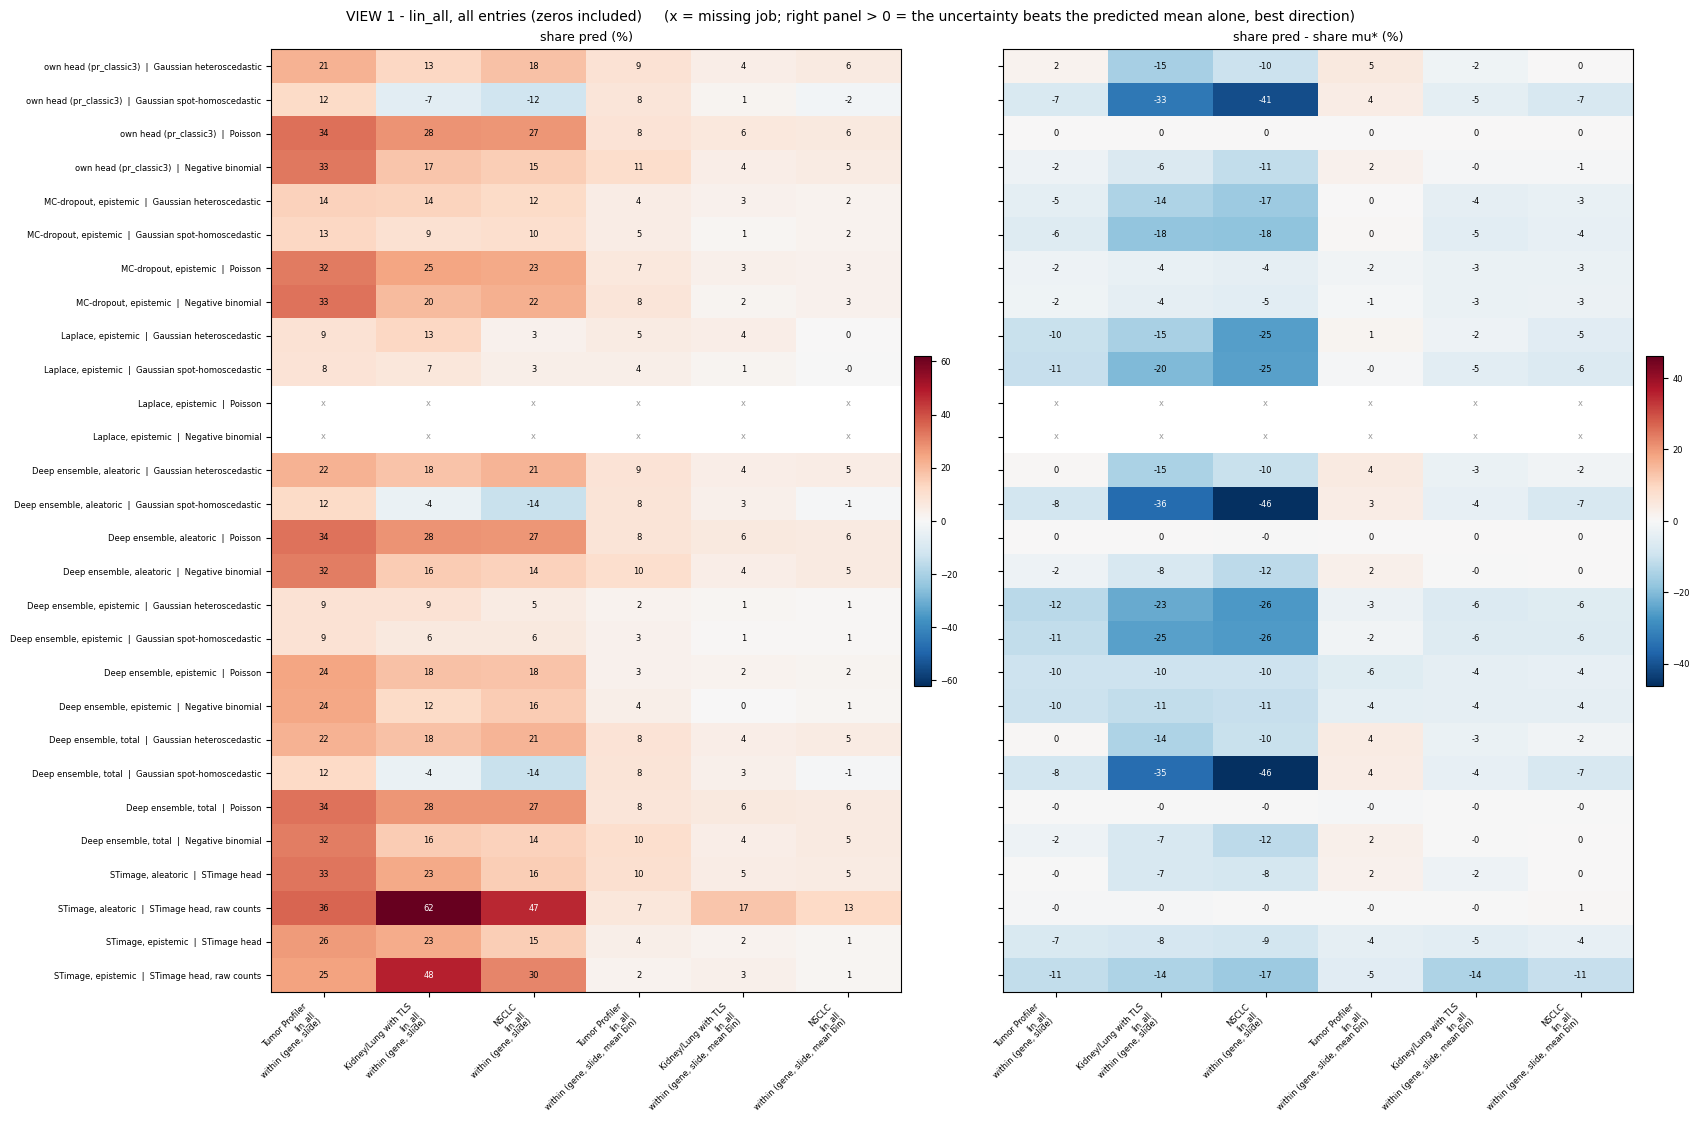


[printed twin - VIEW 1 - lin_all, all entries (zeros included)]
  own head (pr_classic3)  |  Gaussian heteroscedastic             21.4(+2)   12.8(-15)   18.4(-10)    8.8(+5)    4.3(-2)    5.8(+0)
  own head (pr_classic3)  |  Gaussian spot-homoscedastic          12.0(-7)   -6.6(-33)  -12.5(-41)    7.6(+4)    1.5(-5)   -1.5(-7)
  own head (pr_classic3)  |  Poisson                              34.3(+0)   28.0(+0)   27.3(+0)    8.3(+0)    6.3(+0)    6.0(+0)
  own head (pr_classic3)  |  Negative binomial                    32.6(-2)   17.3(-6)   15.3(-11)   10.8(+2)    4.3(-0)    5.1(-1)
  MC-dropout, epistemic  |  Gaussian heteroscedastic              14.4(-5)   13.7(-14)   11.7(-17)    4.4(+0)    2.6(-4)    2.4(-3)
  MC-dropout, epistemic  |  Gaussian spot-homoscedastic           13.0(-6)    9.3(-18)   10.3(-18)    4.5(+0)    1.2(-5)    2.1(-4)
  MC-dropout, epistemic  |  Poisson                               32.1(-2)   24.6(-4)   23.3(-4)    6.6(-2)    3.3(-3)    2.9(-3)
  MC-dropout, ep

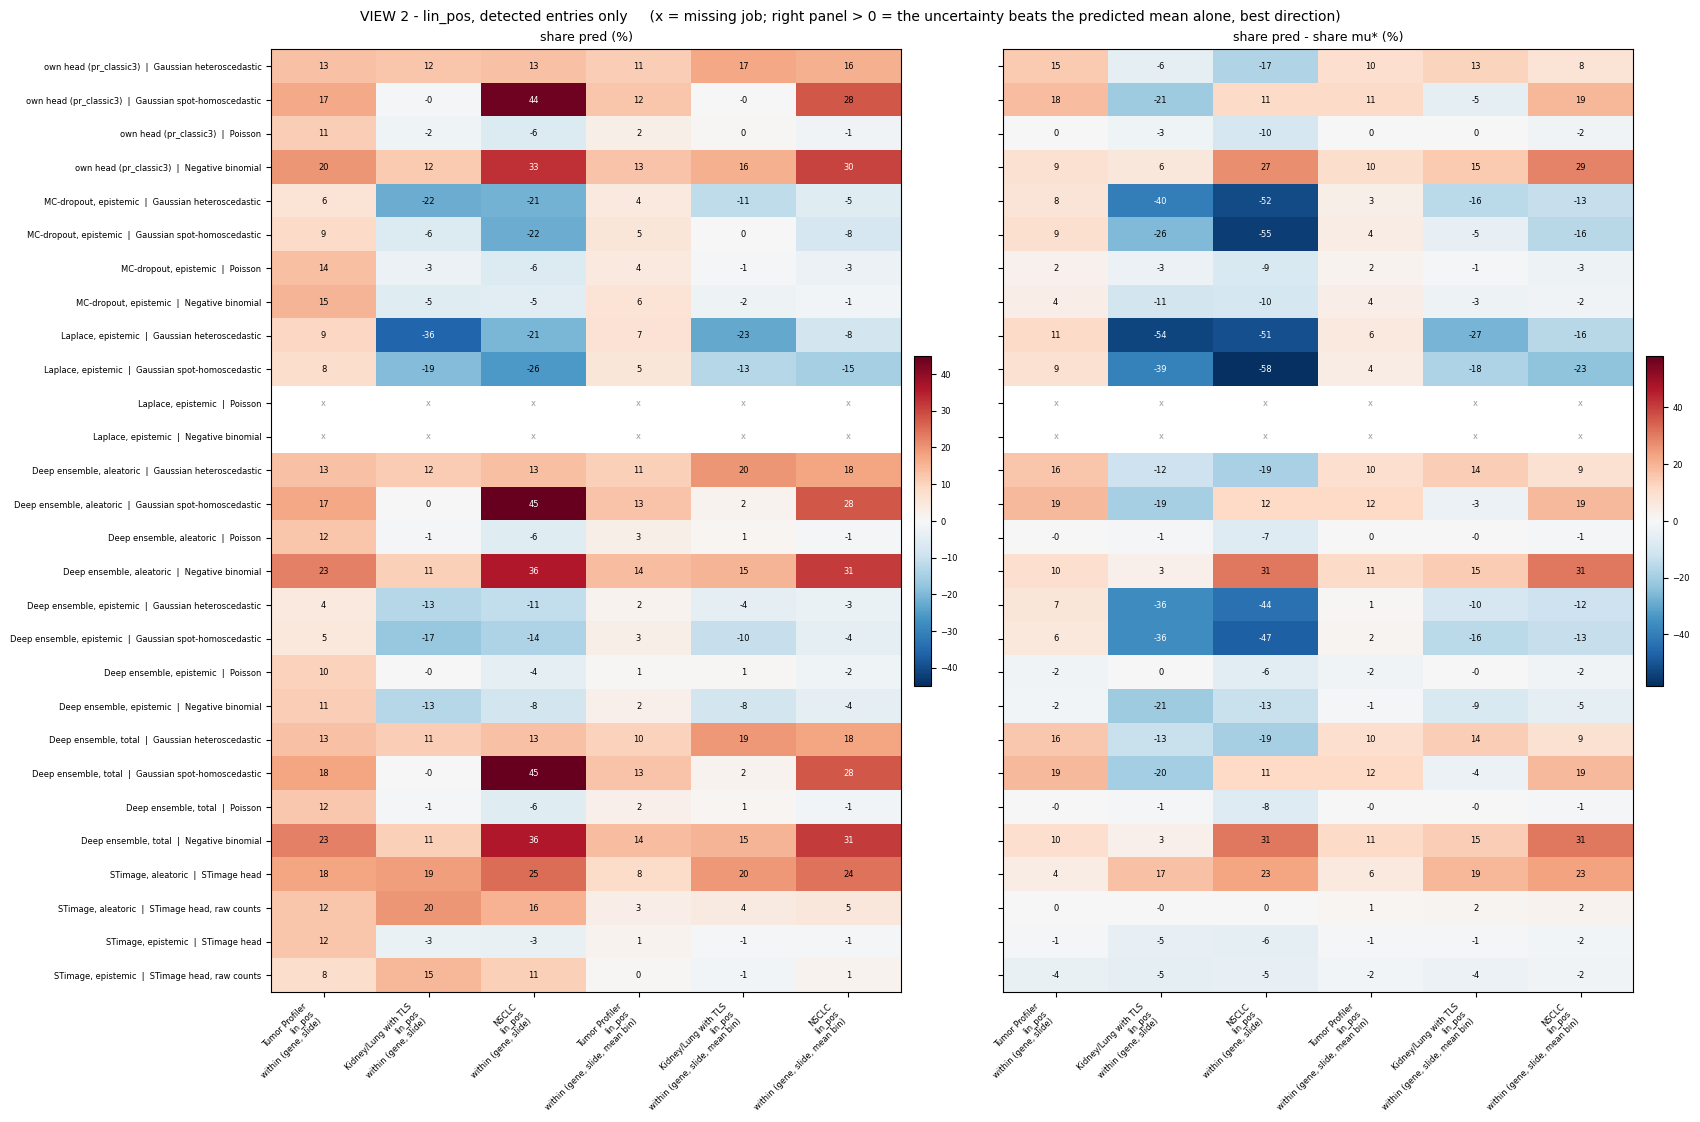


[printed twin - VIEW 2 - lin_pos, detected entries only]
  own head (pr_classic3)  |  Gaussian heteroscedastic             13.0(+15)   12.4(-6)   13.2(-17)   10.9(+10)   17.4(+13)   15.8(+8)
  own head (pr_classic3)  |  Gaussian spot-homoscedastic          17.1(+18)   -0.5(-21)   43.7(+11)   12.3(+11)   -0.1(-5)   27.8(+19)
  own head (pr_classic3)  |  Poisson                              11.2(+0)   -1.8(-3)   -6.3(-10)    2.5(+0)    0.4(+0)   -1.5(-2)
  own head (pr_classic3)  |  Negative binomial                    19.9(+9)   11.6(+6)   33.0(+27)   12.8(+10)   15.9(+15)   30.2(+29)
  MC-dropout, epistemic  |  Gaussian heteroscedastic               6.3(+8)  -22.2(-40)  -21.4(-52)    4.4(+3)  -11.3(-16)   -5.3(-13)
  MC-dropout, epistemic  |  Gaussian spot-homoscedastic            8.6(+9)   -6.1(-26)  -22.3(-55)    5.4(+4)    0.3(-5)   -7.7(-16)
  MC-dropout, epistemic  |  Poisson                               13.7(+2)   -2.5(-3)   -6.1(-9)    4.4(+2)   -0.8(-1)   -2.6(-3)
  MC-dropou

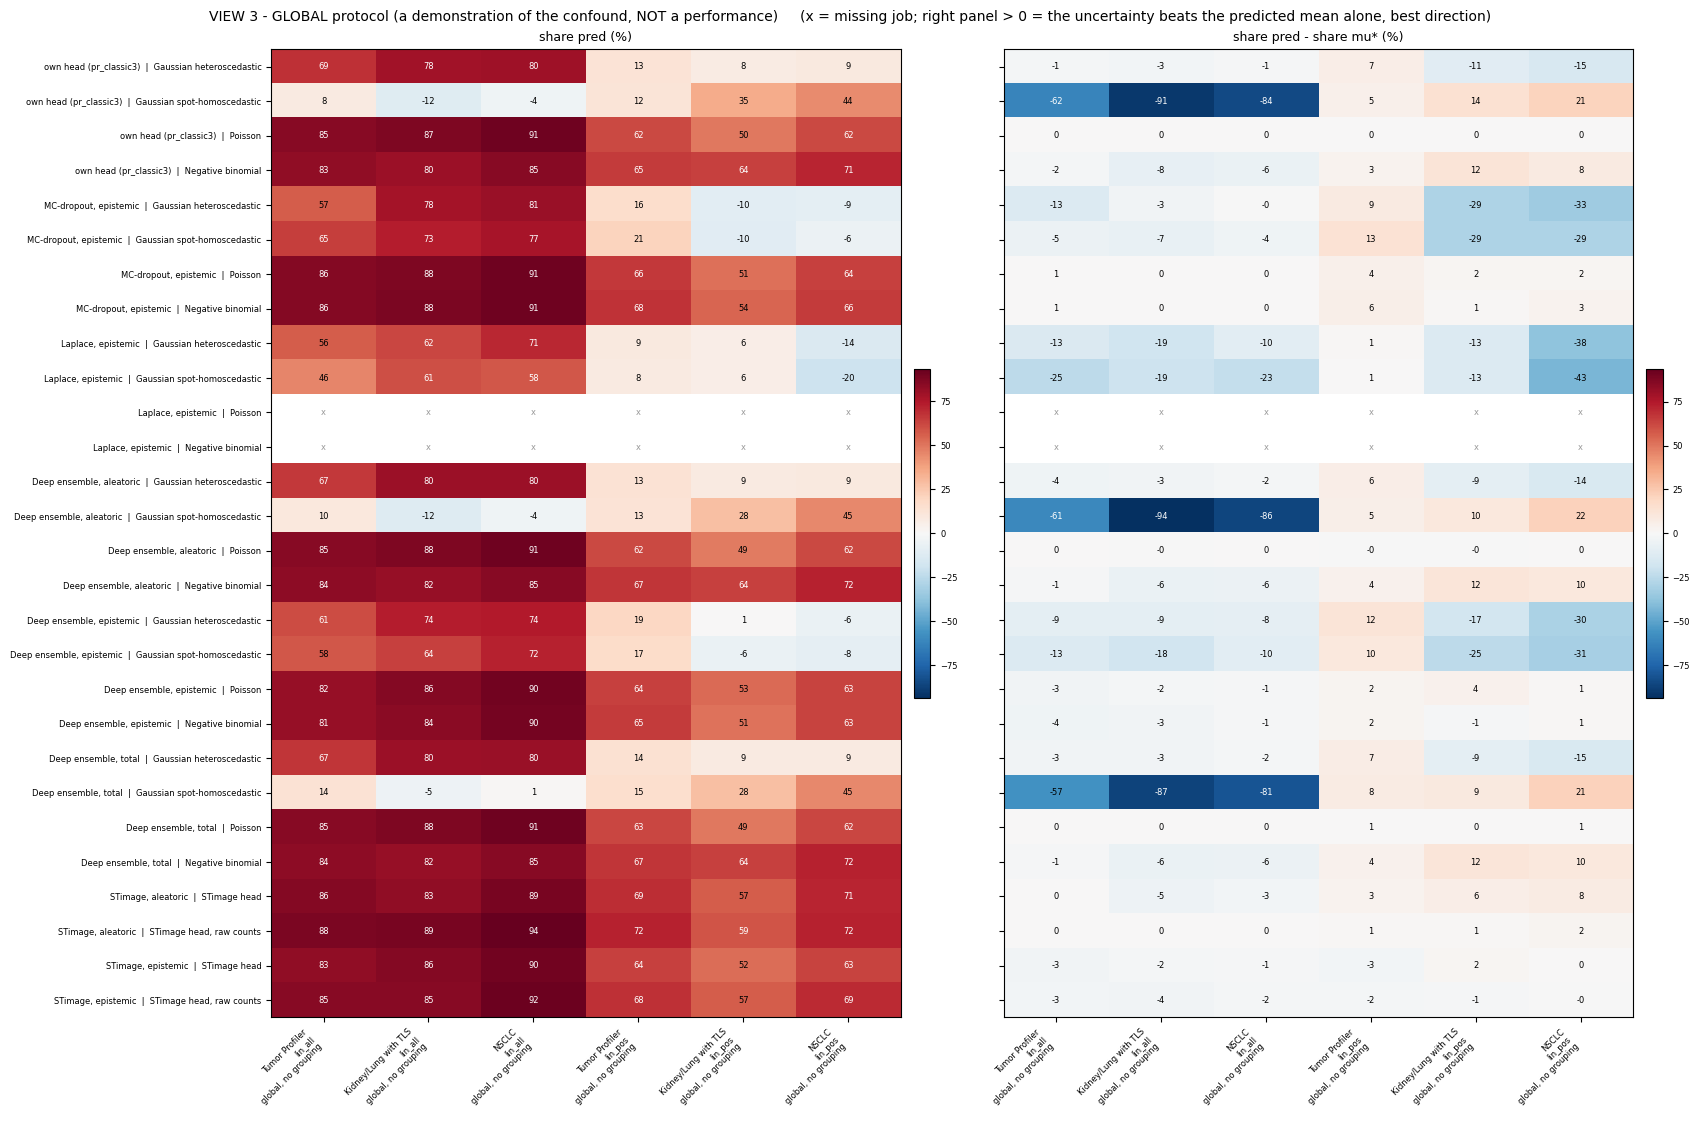


[printed twin - VIEW 3 - GLOBAL protocol (a demonstration of the confound, NOT a performance)]
  own head (pr_classic3)  |  Gaussian heteroscedastic             68.6(-1)   78.3(-3)   79.7(-1)   13.2(+7)    8.0(-11)    9.1(-15)
  own head (pr_classic3)  |  Gaussian spot-homoscedastic           8.1(-62)  -11.5(-91)   -4.0(-84)   12.4(+5)   34.7(+14)   44.5(+21)
  own head (pr_classic3)  |  Poisson                              84.8(+0)   87.4(+0)   91.0(+0)   61.6(+0)   49.5(+0)   61.7(+0)
  own head (pr_classic3)  |  Negative binomial                    83.2(-2)   80.0(-8)   85.4(-6)   65.1(+3)   64.2(+12)   71.3(+8)
  MC-dropout, epistemic  |  Gaussian heteroscedastic              56.7(-13)   77.7(-3)   80.7(-0)   16.3(+9)   -9.7(-29)   -9.0(-33)
  MC-dropout, epistemic  |  Gaussian spot-homoscedastic           64.6(-5)   73.4(-7)   76.9(-4)   21.0(+13)  -10.5(-29)   -5.7(-29)
  MC-dropout, epistemic  |  Poisson                               85.6(+1)   87.6(+0)   91.2(+0)   66.3(+4)   

In [12]:
# ═══ HEATMAPS: the same % as the tables, at a glance ════════════════════════════════════════
# AN ADDITION, not a replacement: the printed tables stay the reference. Nothing is computed
# here that is not already in TAB.
#
# TWO panels per view, and the second is the one that answers the question:
#   left   share pred               what the score recovers of the oracle's reduction
#   right  share pred - share mu*   what it recovers ON TOP of the predicted mean alone, taken
#          in its BEST direction. > 0: the uncertainty adds something. <= 0:
#          redundant with the mean. Comparing to mu_high alone would give a gap a
#          weaker of the two directions would flatter the head.
# DIVERGING scale centered on 0 in both cases, because the sign is what matters: a
# negative value means "worse than sorting nothing" (left) or "worse than the mean alone"
# (right), and a sequential scale would hide it.

import matplotlib.pyplot as plt


def heat_view(cases, protos, title):
    if TAB.empty:
        print("nothing to draw.")
        return
    # Rows = (source, head), in the order of SOURCES, hence the SAME as the printed tables:
    # one moves from one to the other without searching.
    rlab, rkey = [], []
    for src in SOURCES:
        for head in src["heads"]:
            rkey.append((src["key"], head))
            rlab.append(f"{src['label']}  |  {HEAD_LABELS.get(head, head)}")
    cols = [(ds, case, proto) for case in cases for proto in protos for ds in DATASETS]
    clab = [f"{DATASET_LABELS.get(ds, ds)}\n{case}\n{PROTOCOL_LABEL[proto]}"
            for ds, case, proto in cols]

    P = np.full((len(rkey), len(cols)), np.nan)
    G = np.full((len(rkey), len(cols)), np.nan)
    for i, (skey, head) in enumerate(rkey):
        for j, (ds, case, proto) in enumerate(cols):
            r = TAB[(TAB["source"] == skey) & (TAB["head"] == head) & (TAB["dataset"] == ds)
                    & (TAB["case"] == case) & (TAB["protocol"] == proto)]
            if r.empty:
                continue
            r = r.iloc[0]
            P[i, j] = 100 * r["share_pred"]
            G[i, j] = 100 * (r["share_pred"] - r["share_mu_best"])

    fig, axes = plt.subplots(1, 2, figsize=(1.35 * len(cols) + 9.0, 0.30 * len(rkey) + 3.0),
                             sharey=True)
    for ax, M, sub in ((axes[0], P, "share pred (%)"),
                       (axes[1], G, "share pred - share mu* (%)")):
        # Symmetric bounds READ OFF THE DATA: the global view rises toward 90 % while the
        # per-(gene, slide) views top out near 30 %, and a fixed scale would flatten the
        # latter to the point of illegibility.
        v = np.nanmax(np.abs(M)) if np.isfinite(M).any() else 1.0
        im = ax.imshow(M, cmap="RdBu_r", vmin=-v, vmax=v, aspect="auto")
        ax.set_xticks(range(len(cols)))
        ax.set_xticklabels(clab, fontsize=6, rotation=45, ha="right")
        ax.set_title(sub, fontsize=9)
        for i in range(M.shape[0]):
            for j in range(M.shape[1]):
                if np.isfinite(M[i, j]):
                    c = "white" if abs(M[i, j]) > 0.62 * v else "black"
                    ax.text(j, i, f"{M[i, j]:.0f}", ha="center", va="center", fontsize=6, color=c)
                else:
                    # An empty cell is a MISSING job, not a zero. On a diverging scale
                    # white reads as "close to 0", so it has to be said explicitly.
                    ax.text(j, i, "x", ha="center", va="center", fontsize=6, color="0.6")
        fig.colorbar(im, ax=ax, fraction=0.025, pad=0.02).ax.tick_params(labelsize=6)
    axes[0].set_yticks(range(len(rlab)))
    axes[0].set_yticklabels(rlab, fontsize=6)
    fig.suptitle(f"{title}     (x = missing job; right panel > 0 = the uncertainty beats the "
                 f"predicted mean alone, best direction)", fontsize=10)
    fig.tight_layout()
    plt.show()

    # The printed twin of what is DRAWN: a figure is not readable output on its own.
    print(f"\n[printed twin - {title}]")
    for i, lab in enumerate(rlab):
        cells = "  ".join("   x  " if not np.isfinite(P[i, j])
                          else f"{P[i, j]:>5.1f}({G[i, j]:+.0f})" for j in range(len(cols)))
        print(f"  {lab:<62s} {cells}")
    print("  format: share pred (gap vs mu*)   columns: "
          + " | ".join(c.replace(chr(10), " / ") for c in clab))


heat_view(["lin_all"], ["gene_slide", "gene_slide_bin"],
          "VIEW 1 - lin_all, all entries (zeros included)")
heat_view(["lin_pos"], ["gene_slide", "gene_slide_bin"],
          "VIEW 2 - lin_pos, detected entries only")
heat_view(["lin_all", "lin_pos"], ["pooled"],
          "VIEW 3 - GLOBAL protocol (a demonstration of the confound, NOT a performance)")